# Analysis Notebook

1. Controlled bb144 FastSA Stage-2 sweep.
2. bb144 batch: the FastSA (`bb144_n_fastsa_k1000.json`, logged), deterministic and random placements with `naive_n_dag`, plus `naive_dag`.
3. BV / QFT / VQE / general batch (`inputs/qasm_files/general/`): every benchmark with its FastSA config and its `_deterministic` config with `naive_n_dag`, plus `naive_dag`.
4. FastSA log of the bb144 k1000 run.
5. Execution-time bar graphs and summary table, next to the Enola and PowerMove (storage off and on) reference times.
6. AOD loads and unloads (total and the most on one qubit) for naive_n_dag (FastSA, deterministic) and PowerMove (storage off and on).

A deterministic config with `schedule_screen` on has a twin `<name>_noscreen.json` with it off. Both run: the screened one
is "slow", the twin "fast". The bar graphs use the slow run; the summary table shows both as `slow-fast`.

The only qLDPC circuit used is bb144, the [[144,12,12]] bivariate-bicycle syndrome round. Every config that is run must use
PowerMove's acceleration and lattice spacing (2750 m/s², 8 µm), a 10 m/s velocity cap and the trapezoidal movement shape.
The setup cell checks this.
Every file the notebook writes goes to `benchmarks/output/analysis_output/`.

In [1]:
from copy import deepcopy
from pathlib import Path
import csv
import json
import re
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

repo_root = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents) if (p / "src" / "naive_n_dag").is_dir())  # works from benchmarks/ or the repo root
src_dir = repo_root / "src"
if str(src_dir) not in sys.path:
    sys.path.insert(0, str(src_dir))

from naive_dag.main import load_config as load_naive_dag_config
from naive_dag.main import main as naive_dag_main
from naive_n_dag.main import load_config as load_naive_n_dag_config
from naive_n_dag.main import main as naive_n_dag_main

configs_dir = repo_root / "benchmarks" / "configs"
qasm_dir = repo_root / "inputs" / "qasm_files"
analysis_out = repo_root / "benchmarks" / "output" / "analysis_output"
analysis_out.mkdir(parents=True, exist_ok=True)

# bb144 = the [[144,12,12]] bivariate-bicycle syndrome round
# (data q[0..143], X ancillas q[144..215], Z ancillas q[216..287]).
bb144_qasm = qasm_dir / "qLDPC" / "bb_n144_k12_d12_cz_syndrome.qasm"
assert bb144_qasm.exists(), f"Missing QASM file: {bb144_qasm}"

# Enola and PowerMove execution times, precomputed (benchmarks/powermove_script.py).
reference_timings_csv = repo_root / "benchmarks" / "output" / "scheduler_batch_timings.csv"

POWERMOVE_MOTION = {
    "max_acceleration": "2750 m/s^2",
    "max_velocity": "2 m/s",
    "lattice_spacing": "15 micrometers",
    "movement_shape": "Cubic_Spline",
}


def check_motion(config_path: Path, config: dict) -> None:
    """Fail if a config's motion parameters or movement shape differ from POWERMOVE_MOTION."""
    wrong = {k: config.get(k) for k, v in POWERMOVE_MOTION.items() if config.get(k) != v}
    if wrong:
        raise ValueError(f"{config_path.relative_to(repo_root)} differs from PowerMove's motion parameters: {wrong}")


final_time_re = re.compile(r"^final_time:\s*([0-9eE+\-.]+)\s+microsecond")


def parse_final_time_us(schedule_path: Path) -> float:
    for line in schedule_path.read_text(encoding="utf-8").splitlines():
        m = final_time_re.match(line.strip())
        if m:
            return float(m.group(1))
    raise ValueError(f"final_time not found in {schedule_path}")


def screen_variants(config_path: Path) -> list[tuple[Path, str]]:
    """A config with a `<stem>_noscreen.json` twin runs twice: itself as "slow", the twin as "fast"."""
    twin = config_path.with_name(f"{config_path.stem}_noscreen.json")
    return [(config_path, "slow"), (twin, "fast")] if twin.exists() else [(config_path, "")]


def run_naive_n_dag(config_path: Path, qasm_path: Path, output_name: str, seed: int = 0, log: bool = False, variant: str = "") -> dict:
    """Run naive_n_dag into analysis_out; return the timing record."""
    config = load_naive_n_dag_config(config_path)
    check_motion(config_path, config)
    t0 = time.perf_counter()
    exit_code = naive_n_dag_main(
        config,
        str(qasm_path),
        schedule_output_dir=analysis_out,
        config_path=config_path,
        quiet=True,
        seed=seed,
        output_name=output_name,
        log=log,
    )
    wall_seconds = time.perf_counter() - t0
    schedule_path = analysis_out / output_name
    return {
        "solver": "naive_n_dag",
        "placement": config["fill_strategy"],
        "variant": variant,
        "config": str(config_path.relative_to(repo_root)),
        "qasm": str(qasm_path.relative_to(repo_root)),
        "Tcomp (s)": wall_seconds,
        "Texec (µs)": parse_final_time_us(schedule_path),
        "exit_code": exit_code,
        "output_file": str(schedule_path.relative_to(repo_root)),
    }


def run_naive_dag(config_path: Path, qasm_path: Path, output_name: str, seed: int = 0) -> dict:
    """Run naive_dag (always naive placement) into analysis_out; return the timing record."""
    config = load_naive_dag_config(config_path)
    check_motion(config_path, config)
    t0 = time.perf_counter()
    exit_code = naive_dag_main(
        config,
        str(qasm_path),
        schedule_output_dir=analysis_out,
        config_path=config_path,
        quiet=True,
        seed=seed,
    )
    wall_seconds = time.perf_counter() - t0
    # naive_dag names its schedule after the QASM; rename it so runs do not overwrite each other.
    target = analysis_out / output_name
    (analysis_out / f"{qasm_path.stem}.schedule.txt").replace(target)
    return {
        "solver": "naive_dag",
        "placement": "naive",
        "config": str(config_path.relative_to(repo_root)),
        "qasm": str(qasm_path.relative_to(repo_root)),
        "Tcomp (s)": wall_seconds,
        "Texec (µs)": parse_final_time_us(target),
        "exit_code": exit_code,
        "output_file": str(target.relative_to(repo_root)),
    }

## 1) Controlled bb144 Stage-2 sweep (`k = stage2_iterations`)

Only `Fastsa_fill.stage2_iterations` changes. All other parameters remain fixed.

In [19]:
base_config_path = configs_dir / "bb144" / "bb144_n_fastsa_k7.json"
base_config = load_naive_n_dag_config(base_config_path)
check_motion(base_config_path, base_config)
print("base_config:", base_config_path.relative_to(repo_root))
print("qasm:", bb144_qasm.relative_to(repo_root))

stage2_values = [0, 1, 2, 3, 5, 7, 10, 20, 50, 100, 1000,10000]
seeds = [0]

base_fastsa = base_config.get("Fastsa_fill", {})
fixed_fastsa = {
    "stage1_iterations": int(base_fastsa.get("stage1_iterations", 2)),
    "c": float(base_fastsa.get("c", 100)),
    "stage3_max_iterations": int(base_fastsa.get("stage3_max_iterations", 0)),
    "stage3_section_size": int(base_fastsa.get("stage3_section_size", 3)),
}

print("fixed_fastsa:", fixed_fastsa)
print("stage2_values:", stage2_values)
print("seeds:", seeds)

base_config: benchmarks/configs/bb144/bb144_n_fastsa_k7.json
qasm: inputs/qasm_files/qLDPC/bb_n144_k12_d12_cz_syndrome.qasm
fixed_fastsa: {'stage1_iterations': 2, 'c': 100.0, 'stage3_max_iterations': 0, 'stage3_section_size': 3}
stage2_values: [0, 1, 2, 3, 5, 7, 10, 20, 50, 100, 1000, 10000]
seeds: [0]


In [20]:
def run_one(stage2_iterations: int, seed: int) -> dict:
    cfg = deepcopy(base_config)
    cfg["Fastsa_fill"] = dict(fixed_fastsa)
    cfg["Fastsa_fill"]["stage2_iterations"] = int(stage2_iterations)

    run_tag = f"bb144_stage2_k{stage2_iterations}_seed{seed}"
    output_name = f"{run_tag}.schedule.txt"

    t0 = time.perf_counter()
    exit_code = naive_n_dag_main(
        cfg,
        str(bb144_qasm),
        schedule_output_dir=analysis_out,
        config_path=base_config_path,
        quiet=True,
        seed=seed,
        output_name=output_name,
        log=True,
    )
    wall_seconds = time.perf_counter() - t0

    schedule_path = analysis_out / output_name
    log_path = analysis_out / f"{run_tag}.fastsa_log.csv"
    log_df = pd.read_csv(log_path)

    return {
        "k": stage2_iterations,
        "seed": seed,
        "exit_code": exit_code,
        "wall_seconds": wall_seconds,
        "final_time_us": parse_final_time_us(schedule_path),
        "best_cost_min": float(log_df["best_cost"].min()),
        "best_cost_last": float(log_df["best_cost"].iloc[-1]),
        "log_steps": int(len(log_df)),
        "schedule_file": str(schedule_path.relative_to(repo_root)),
        "log_file": str(log_path.relative_to(repo_root)),
    }


records = []
for k in stage2_values:
    for seed in seeds:
        rec = run_one(k, seed)
        records.append(rec)
        print(f"k={k:>4} seed={seed} final_time_us={rec['final_time_us']:.3f} best_cost_min={rec['best_cost_min']:.6f}")

results_df = pd.DataFrame(records).sort_values(["k", "seed"]).reset_index(drop=True)
results_df.to_csv(analysis_out / "bb144_stage2_sweep.csv", index=False)
summary_df = (
    results_df.groupby("k", as_index=False)
    .agg(
        final_time_us_mean=("final_time_us", "mean"),
        best_cost_min_mean=("best_cost_min", "mean"),
        wall_seconds_mean=("wall_seconds", "mean"),
    )
    .sort_values("k")
    .reset_index(drop=True)
)
results_df

k=   0 seed=0 final_time_us=279440.585 best_cost_min=283943.192309
k=   1 seed=0 final_time_us=279440.585 best_cost_min=283943.192309
k=   2 seed=0 final_time_us=279440.585 best_cost_min=283943.192309
k=   3 seed=0 final_time_us=279440.585 best_cost_min=283943.192309
k=   5 seed=0 final_time_us=279440.585 best_cost_min=283943.192309
k=   7 seed=0 final_time_us=238158.514 best_cost_min=282370.649864
k=  10 seed=0 final_time_us=259881.046 best_cost_min=281122.594742
k=  20 seed=0 final_time_us=259881.046 best_cost_min=281122.594742
k=  50 seed=0 final_time_us=266590.980 best_cost_min=272604.087114
k= 100 seed=0 final_time_us=266590.980 best_cost_min=272604.087114
k=1000 seed=0 final_time_us=264649.654 best_cost_min=259424.223729
k=10000 seed=0 final_time_us=264649.654 best_cost_min=259424.223729


,k,seed,exit_code,wall_seconds,final_time_us,best_cost_min,best_cost_last,log_steps,schedule_file,log_file
0,0,0,0,1.734243,279440.585496,283943.192309,283943.192309,3,benchmarks/output/analysis_output/bb144_stage2...,benchmarks/output/analysis_output/bb144_stage2...
1,1,0,0,1.736992,279440.585496,283943.192309,283943.192309,4,benchmarks/output/analysis_output/bb144_stage2...,benchmarks/output/analysis_output/bb144_stage2...
2,2,0,0,1.679471,279440.585496,283943.192309,283943.192309,5,benchmarks/output/analysis_output/bb144_stage2...,benchmarks/output/analysis_output/bb144_stage2...
3,3,0,0,1.665052,279440.585496,283943.192309,283943.192309,6,benchmarks/output/analysis_output/bb144_stage2...,benchmarks/output/analysis_output/bb144_stage2...
4,5,0,0,1.683443,279440.585496,283943.192309,283943.192309,8,benchmarks/output/analysis_output/bb144_stage2...,benchmarks/output/analysis_output/bb144_stage2...
5,7,0,0,1.654101,238158.514353,282370.649864,282370.649864,10,benchmarks/output/analysis_output/bb144_stage2...,benchmarks/output/analysis_output/bb144_stage2...
6,10,0,0,1.676919,259881.046243,281122.594742,281122.594742,13,benchmarks/output/analysis_output/bb144_stage2...,benchmarks/output/analysis_output/bb144_stage2...
7,20,0,0,1.703173,259881.046243,281122.594742,281122.594742,23,benchmarks/output/analysis_output/bb144_stage2...,benchmarks/output/analysis_output/bb144_stage2...
8,50,0,0,1.895209,266590.979822,272604.087114,272604.087114,53,benchmarks/output/analysis_output/bb144_stage2...,benchmarks/output/analysis_output/bb144_stage2...
9,100,0,0,1.968889,266590.979822,272604.087114,272604.087114,103,benchmarks/output/analysis_output/bb144_stage2...,benchmarks/output/analysis_output/bb144_stage2...


`k` is the number of greedy Stage-2 iterations. The next cell plots both the FastSA objective and the schedule time.

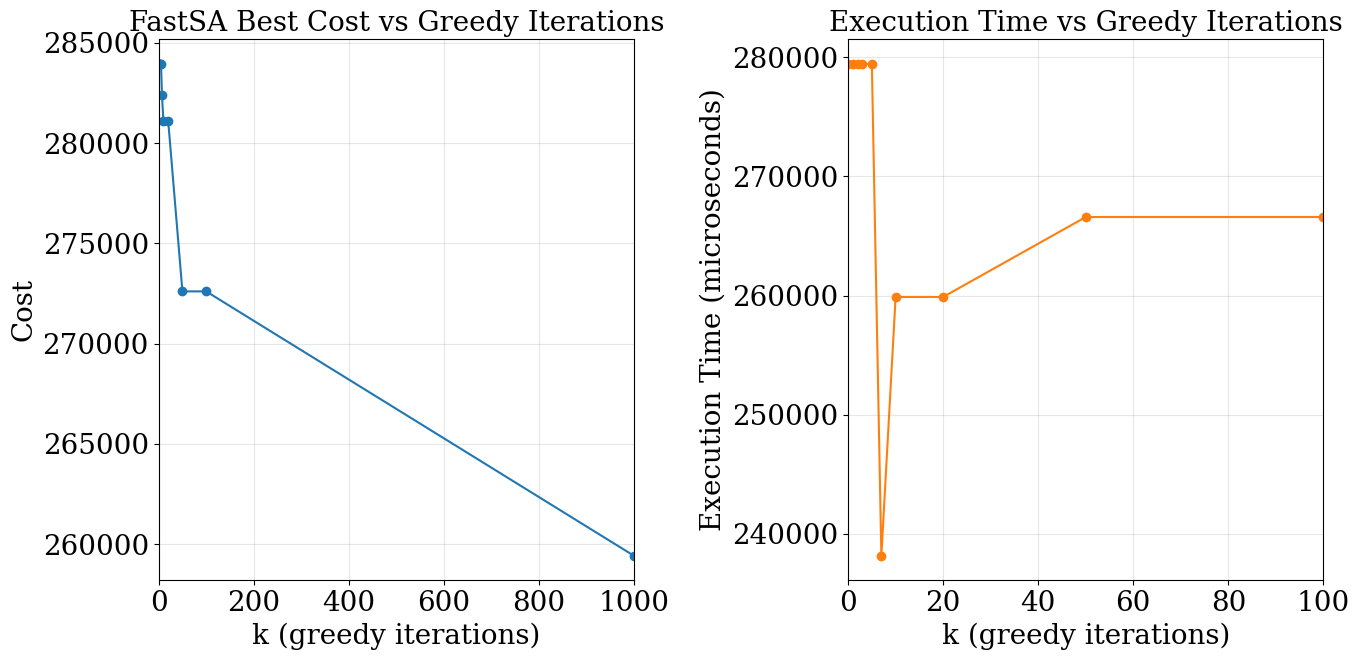

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(14, 7))

axes[0].plot(summary_df["k"], summary_df["best_cost_min_mean"], marker="o")
axes[0].set_title("FastSA Best Cost vs Greedy Iterations")
axes[0].set_xlabel("k (greedy iterations)")
axes[0].set_ylabel("Cost")
axes[0].grid(alpha=0.3)
axes[0].set_xlim(0, 1000)

axes[1].plot(summary_df["k"], summary_df["final_time_us_mean"], marker="o", color="tab:orange")
axes[1].set_title("Execution Time vs Greedy Iterations")
axes[1].set_xlabel("k (greedy iterations)")
axes[1].set_ylabel("Execution Time (microseconds)")
axes[1].grid(alpha=0.3)
axes[1].set_xlim(0, 100)

plt.tight_layout()
fig.savefig(analysis_out / "bb144_stage2_sweep.pdf", bbox_inches="tight")
plt.show()

## 2) bb144 batch: FastSA, deterministic and random placement

`naive_n_dag` runs once per placement config. `naive_dag` always uses its own naive placement, so it runs once.
The FastSA run writes its log (`--log`) for section 4. The deterministic config also runs its `_noscreen` twin.

In [22]:
bb144_label = "[[144,12,12]]"
bb144_configs = {
    "fastsa": configs_dir / "bb144" / "bb144_n_fastsa_k1000.json",
    "deterministic": configs_dir / "bb144" / "bb144_n_deterministic_powermove.json",
    "random": configs_dir / "bb144" / "bb144_n_random.json",
}

bb144_records = []
for placement, cfg_path in bb144_configs.items():
    for path, variant in screen_variants(cfg_path):
        rec = run_naive_n_dag(
            path,
            bb144_qasm,
            f"{path.stem}.naive_n_dag.schedule.txt",
            log=placement == "fastsa",
            variant=variant,
        )
        bb144_records.append({"Benchmark": bb144_label, **rec})
        print(f"naive_n_dag ({placement}{', ' + variant if variant else ''}): Texec={rec['Texec (µs)']:.1f} µs, Tcomp={rec['Tcomp (s)']:.1f} s")

rec = run_naive_dag(bb144_configs["fastsa"], bb144_qasm, "bb144.naive_dag.schedule.txt")
bb144_records.append({"Benchmark": bb144_label, **rec})
print(f"naive_dag: Texec={rec['Texec (µs)']:.1f} µs, Tcomp={rec['Tcomp (s)']:.1f} s")

bb144_df = pd.DataFrame(bb144_records)
bb144_df.to_csv(analysis_out / "bb144_batch_timings.csv", index=False)
bb144_df

naive_n_dag (fastsa): Texec=456548.3 µs, Tcomp=187.0 s
naive_n_dag (deterministic, slow): Texec=10989.3 µs, Tcomp=180.5 s
naive_n_dag (deterministic, fast): Texec=14136.3 µs, Tcomp=87.5 s
naive_n_dag (random): Texec=514577.3 µs, Tcomp=1.4 s
811552.3305655667 microsecond
schedule_file=/home/gage/Quantum_Class/Phys765/benchmarks/output/analysis_output/bb_n144_k12_d12_cz_syndrome.schedule.txt
naive_dag: Texec=811552.3 µs, Tcomp=0.6 s


,Benchmark,solver,placement,variant,config,qasm,Tcomp (s),Texec (µs),exit_code,output_file
0,"[[144,12,12]]",naive_n_dag,fastsa,,benchmarks/configs/bb144/bb144_n_fastsa_k1000....,inputs/qasm_files/qLDPC/bb_n144_k12_d12_cz_syn...,186.953557,456548.276195,0,benchmarks/output/analysis_output/bb144_n_fast...
1,"[[144,12,12]]",naive_n_dag,deterministic,slow,benchmarks/configs/bb144/bb144_n_deterministic...,inputs/qasm_files/qLDPC/bb_n144_k12_d12_cz_syn...,180.493140,10989.295422,0,benchmarks/output/analysis_output/bb144_n_dete...
2,"[[144,12,12]]",naive_n_dag,deterministic,fast,benchmarks/configs/bb144/bb144_n_deterministic...,inputs/qasm_files/qLDPC/bb_n144_k12_d12_cz_syn...,87.521868,14136.285697,0,benchmarks/output/analysis_output/bb144_n_dete...
3,"[[144,12,12]]",naive_n_dag,random,,benchmarks/configs/bb144/bb144_n_random.json,inputs/qasm_files/qLDPC/bb_n144_k12_d12_cz_syn...,1.434623,514577.311561,0,benchmarks/output/analysis_output/bb144_n_rand...
4,"[[144,12,12]]",naive_dag,naive,NaN,benchmarks/configs/bb144/bb144_n_fastsa_k1000....,inputs/qasm_files/qLDPC/bb_n144_k12_d12_cz_syn...,0.574598,811552.330566,0,benchmarks/output/analysis_output/bb144.naive_...


## 3) BV / QFT / VQE / general batch: FastSA and deterministic placement

Each benchmark runs `naive_n_dag` with its FastSA config (`<name>.json`) and its deterministic config
(`<name>_deterministic.json`, plus its `_noscreen` twin if there is one), then `naive_dag` once.

In [23]:
benchmarks = {
    # label: (config family, config stem, QASM file)
    "BV-14": ("bv", "bv_n14", "bv_n14.qasm"),
    "BV-50": ("bv", "bv_n50", "bv_n50.qasm"),
    "BV-70": ("bv", "bv_n70", "bv_n70.qasm"),
    "QFT-18": ("qft", "qft_n18", "qft_n18_transpiled.qasm"),
    "QFT-29": ("qft", "qft_n29", "qft_n29_transpiled.qasm"),
    "QFT-63": ("qft", "qft_n63", "qft_n63_transpiled.qasm"),
    "VQE-30": ("vqe", "vqe_n30", "vqe_n30.qasm"),
    "VQE-50": ("vqe", "vqe_n50", "vqe_n50.qasm"),
    "Adder-18": ("general", "adder_18", "adder_18.qasm"),
    "QV-20": ("general", "qv_20", "qv_20.qasm"),
    "Heisenberg-24": ("general", "heisenberg_24", "heisenberg_24.qasm"),
    "QAOA-24": ("general", "qaoa_24", "qaoa_24.qasm"),
    "Random-24": ("general", "random_24", "random_24.qasm"),
}

general_records = []
for label, (family, stem, qasm_name) in benchmarks.items():
    qasm_path = qasm_dir / family / qasm_name
    for config_stem in (stem, f"{stem}_deterministic"):
        for cfg_path, variant in screen_variants(configs_dir / family / f"{config_stem}.json"):
            rec = run_naive_n_dag(cfg_path, qasm_path, f"{cfg_path.stem}.naive_n_dag.schedule.txt", variant=variant)
            general_records.append({"Benchmark": label, **rec})
            print(f"{label} naive_n_dag ({rec['placement']}{', ' + variant if variant else ''}): Texec={rec['Texec (µs)']:.1f} µs, Tcomp={rec['Tcomp (s)']:.1f} s")

    rec = run_naive_dag(configs_dir / family / f"{stem}.json", qasm_path, f"{stem}.naive_dag.schedule.txt")
    general_records.append({"Benchmark": label, **rec})
    print(f"{label} naive_dag: Texec={rec['Texec (µs)']:.1f} µs, Tcomp={rec['Tcomp (s)']:.1f} s")

general_df = pd.DataFrame(general_records)
general_df.to_csv(analysis_out / "general_batch_timings.csv", index=False)
general_df

BV-14 naive_n_dag (fastsa): Texec=3736.7 µs, Tcomp=64.9 s
BV-14 naive_n_dag (deterministic): Texec=4056.6 µs, Tcomp=0.0 s
4755.541409821137 microsecond
schedule_file=/home/gage/Quantum_Class/Phys765/benchmarks/output/analysis_output/bv_n14.schedule.txt
BV-14 naive_dag: Texec=4755.5 µs, Tcomp=0.0 s
BV-50 naive_n_dag (fastsa): Texec=7930.8 µs, Tcomp=25.0 s
BV-50 naive_n_dag (deterministic): Texec=7401.7 µs, Tcomp=0.1 s
11084.578273284058 microsecond
schedule_file=/home/gage/Quantum_Class/Phys765/benchmarks/output/analysis_output/bv_n50.schedule.txt
BV-50 naive_dag: Texec=11084.6 µs, Tcomp=0.0 s
BV-70 naive_n_dag (fastsa): Texec=16739.8 µs, Tcomp=24.8 s
BV-70 naive_n_dag (deterministic): Texec=14010.1 µs, Tcomp=0.2 s
17756.664657365574 microsecond
schedule_file=/home/gage/Quantum_Class/Phys765/benchmarks/output/analysis_output/bv_n70.schedule.txt
BV-70 naive_dag: Texec=17756.7 µs, Tcomp=0.1 s
QFT-18 naive_n_dag (fastsa): Texec=58855.8 µs, Tcomp=210.5 s
QFT-18 naive_n_dag (deterministic): 

,Benchmark,solver,placement,variant,config,qasm,Tcomp (s),Texec (µs),exit_code,output_file
0,BV-14,naive_n_dag,fastsa,,benchmarks/configs/bv/bv_n14.json,inputs/qasm_files/bv/bv_n14.qasm,64.941254,3.736676e+03,0,benchmarks/output/analysis_output/bv_n14.naive...
1,BV-14,naive_n_dag,deterministic,,benchmarks/configs/bv/bv_n14_deterministic.json,inputs/qasm_files/bv/bv_n14.qasm,0.047328,4.056557e+03,0,benchmarks/output/analysis_output/bv_n14_deter...
2,BV-14,naive_dag,naive,NaN,benchmarks/configs/bv/bv_n14.json,inputs/qasm_files/bv/bv_n14.qasm,0.025103,4.755541e+03,0,benchmarks/output/analysis_output/bv_n14.naive...
3,BV-50,naive_n_dag,fastsa,,benchmarks/configs/bv/bv_n50.json,inputs/qasm_files/bv/bv_n50.qasm,25.017223,7.930817e+03,0,benchmarks/output/analysis_output/bv_n50.naive...
4,BV-50,naive_n_dag,deterministic,,benchmarks/configs/bv/bv_n50_deterministic.json,inputs/qasm_files/bv/bv_n50.qasm,0.068905,7.401731e+03,0,benchmarks/output/analysis_output/bv_n50_deter...
5,BV-50,naive_dag,naive,NaN,benchmarks/configs/bv/bv_n50.json,inputs/qasm_files/bv/bv_n50.qasm,0.036825,1.108458e+04,0,benchmarks/output/analysis_output/bv_n50.naive...
6,BV-70,naive_n_dag,fastsa,,benchmarks/configs/bv/bv_n70.json,inputs/qasm_files/bv/bv_n70.qasm,24.841873,1.673979e+04,0,benchmarks/output/analysis_output/bv_n70.naive...
7,BV-70,naive_n_dag,deterministic,,benchmarks/configs/bv/bv_n70_deterministic.json,inputs/qasm_files/bv/bv_n70.qasm,0.199088,1.401011e+04,0,benchmarks/output/analysis_output/bv_n70_deter...
8,BV-70,naive_dag,naive,NaN,benchmarks/configs/bv/bv_n70.json,inputs/qasm_files/bv/bv_n70.qasm,0.057298,1.775666e+04,0,benchmarks/output/analysis_output/bv_n70.naive...
9,QFT-18,naive_n_dag,fastsa,,benchmarks/configs/qft/qft_n18.json,inputs/qasm_files/qft/qft_n18_transpiled.qasm,210.548337,5.885582e+04,0,benchmarks/output/analysis_output/qft_n18.naiv...


## 4) FastSA log for `bb144_n_fastsa_k1000`

Plots the log written by the bb144 FastSA run in section 2.

Using log: benchmarks/output/analysis_output/bb144_n_fastsa_k1000.naive_n_dag.fastsa_log.csv


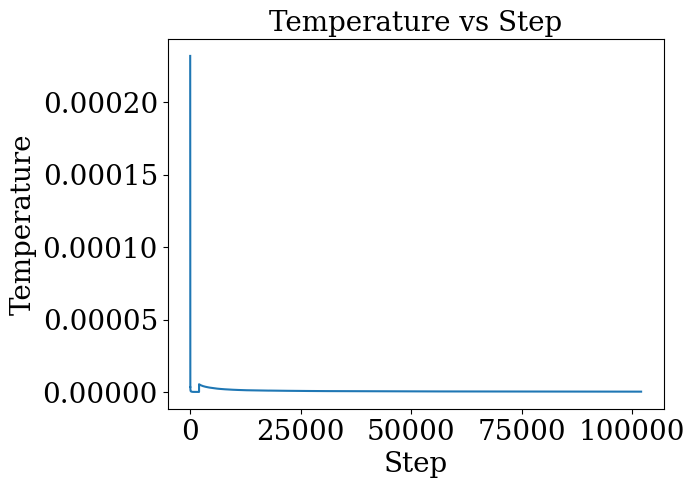

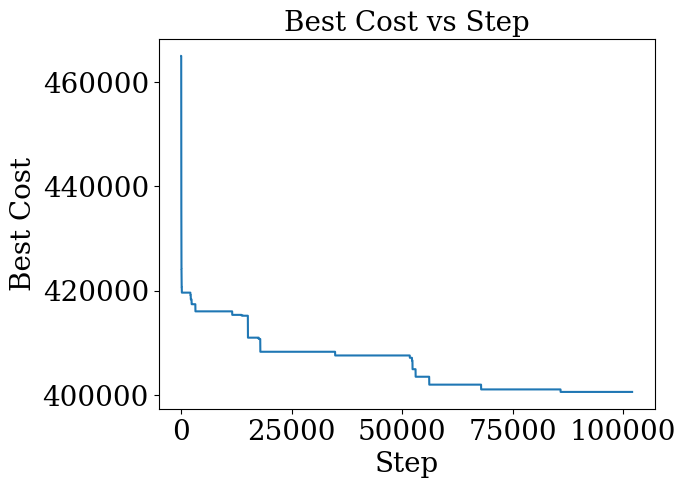

In [24]:
def plot_fastsa_csv(filepath: Path, name: str):
    steps, best_costs, temperatures = [], [], []
    with open(filepath, "r") as f:
        for row in csv.DictReader(f):
            steps.append(int(row["step"]))
            best_costs.append(float(row["best_cost"]))
            temperatures.append(float(row["temperature"]))

    # The first two steps are stage-1 setup; skip them.
    for values, ylabel, suffix in ((temperatures, "Temperature", "temperature"), (best_costs, "Best Cost", "best_cost")):
        fig = plt.figure()
        plt.plot(steps[2:], values[2:])
        plt.xlabel("Step")
        plt.ylabel(ylabel)
        plt.title(f"{ylabel} vs Step")
        fig.savefig(analysis_out / f"{name}.{suffix}.pdf", bbox_inches="tight")
        plt.show()


log_path = analysis_out / "bb144_n_fastsa_k1000.naive_n_dag.fastsa_log.csv"
if not log_path.exists():
    raise FileNotFoundError(f"{log_path.relative_to(repo_root)} not found. Run the bb144 batch cell first.")

print("Using log:", log_path.relative_to(repo_root))
plot_fastsa_csv(log_path, "bb144_n_fastsa_k1000.fastsa_log")

## 5) Execution-time bar graphs

Combines this notebook's runs (sections 2 and 3) with the Enola and PowerMove (storage off and on) reference times, and writes the combined
table to `analysis_output/scheduler_batch_timings.csv`. The random bb144 placement stays in the CSV but is left out of the plots and the summary table. The plots use the
slow (screened) deterministic run; the fast one is in the CSV and the table.

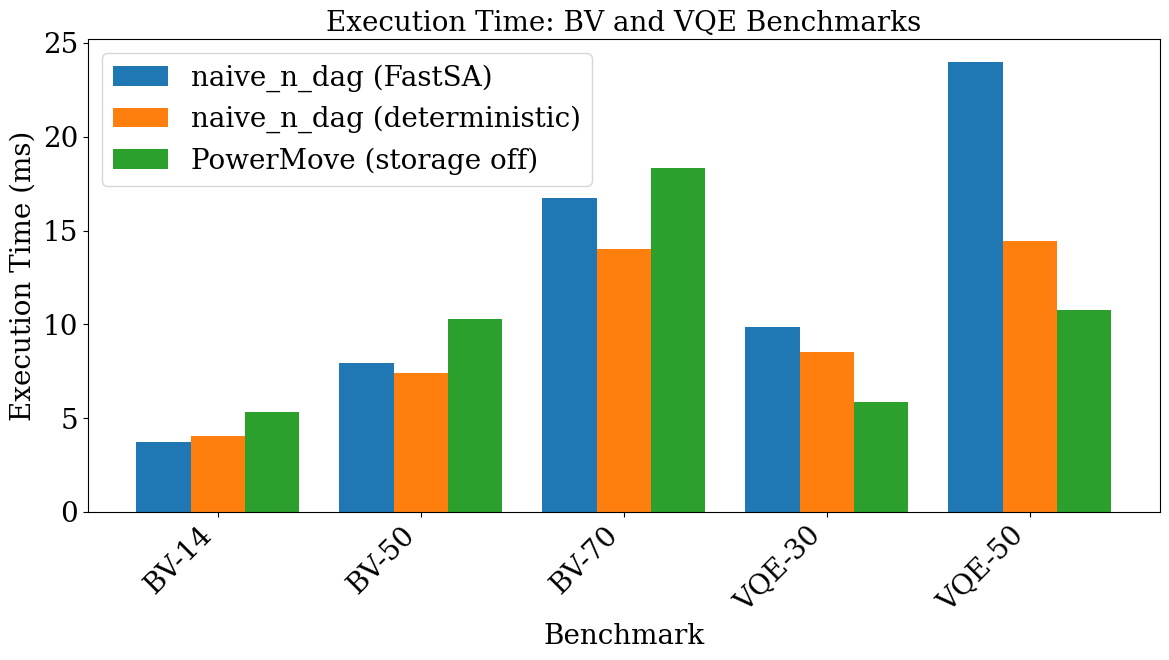

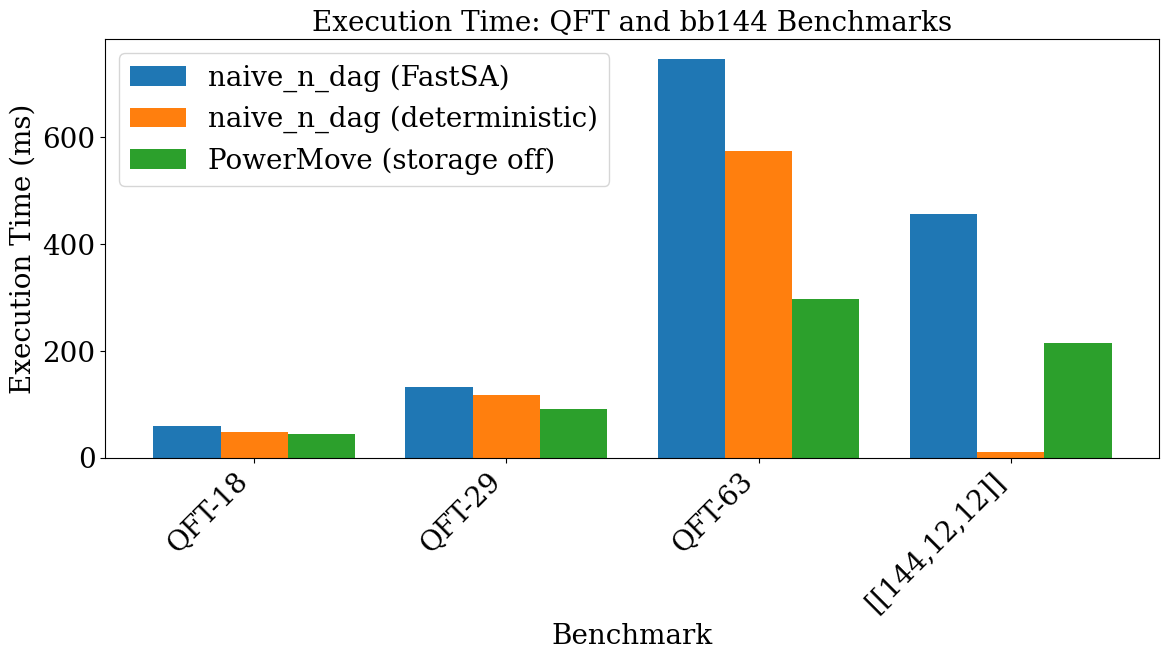

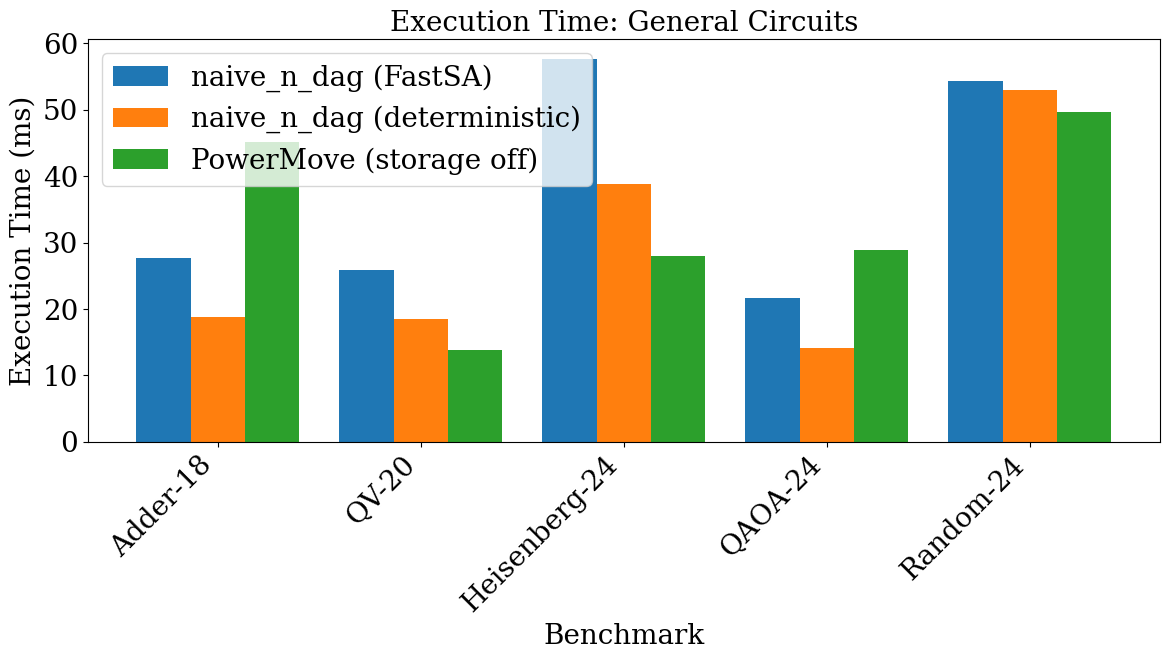

In [2]:
bb144_label = "[[144,12,12]]"
runs = pd.concat(
    [pd.read_csv(analysis_out / name, encoding="utf-8") for name in ("bb144_batch_timings.csv", "general_batch_timings.csv")],
    ignore_index=True,
)
runs["solver"] = np.where(
    runs["solver"] == "naive_n_dag",
    "naive_n_dag (" + runs["placement"].replace({"fastsa": "FastSA"}) + ")",
    runs["solver"],
)

reference = pd.read_csv(reference_timings_csv, encoding="utf-8")
reference.columns = reference.columns.str.strip()
reference = reference[reference["solver"].isin(["Enola", "PowerMove", "PowerMove (storage on)"])]
# The reference CSV keeps PowerMove storage-off runs as "PowerMove".
reference["solver"] = reference["solver"].replace({"PowerMove": "PowerMove (storage off)"})
reference = reference.rename(columns={"qasm_arg": "qasm", "config_json": "config"})

df = pd.concat([runs, reference], ignore_index=True)
df.to_csv(analysis_out / "scheduler_batch_timings.csv", index=False)
df = df.rename(columns={"Texec (µs)": "Texec_us", "Tcomp (s)": "Tcomp_s"})
df["Texec_ms"] = df["Texec_us"] / 1000.0

# Final displayed figure width on poster:
# 0.9 * 0.32 * 42 in = 12.096 in
POSTER_WIDTH_IN = 42
COLUMN_FRAC = 0.32
FIG_FRAC = 0.9
FINAL_FIG_WIDTH = POSTER_WIDTH_IN * COLUMN_FRAC * FIG_FRAC  # 12.096 in

# Match poster font size
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    "font.size": 20,
    "axes.titlesize": 20,
    "axes.labelsize": 20,
    "xtick.labelsize": 20,
    "ytick.labelsize": 20,
    "legend.fontsize": 20,
    "mathtext.fontset": "stix",
})

solvers = ["naive_n_dag (FastSA)","naive_n_dag (deterministic)", "PowerMove (storage off)"]#, "PowerMove (storage on)"]#["naive_n_dag (FastSA)", "naive_n_dag (deterministic)", "naive_dag", "Enola", "PowerMove (storage off)", "PowerMove (storage on)"]

group1 = ["BV-14", "BV-50", "BV-70", "VQE-30", "VQE-50"]
group2 = ["QFT-18", "QFT-29", "QFT-63", bb144_label]
group3 = ["Adder-18", "QV-20", "Heisenberg-24", "QAOA-24", "Random-24"]


def plot_group(benchmarks, title, output_file):
    data = {solver: [] for solver in solvers}
    for bench in benchmarks:
        subset = df[(df["Benchmark"] == bench) & (df["variant"] != "fast")]
        for solver in solvers:
            row = subset[subset["solver"] == solver]
            data[solver].append(row["Texec_ms"].values[0] if not row.empty else 0)

    x = np.arange(len(benchmarks))
    width = 0.8 / len(solvers)

    fig, ax = plt.subplots(figsize=(FINAL_FIG_WIDTH, 7.0))
    for i, solver in enumerate(solvers):
        ax.bar(x + i * width, data[solver], width, label=solver)

    ax.set_xlabel("Benchmark")
    ax.set_ylabel("Execution Time (ms)")
    ax.set_title(title)
    ax.set_xticks(x + width * (len(solvers) - 1) / 2)
    ax.set_xticklabels(benchmarks, rotation=45, ha="right")
    ax.legend()

    fig.tight_layout()
    fig.savefig(analysis_out / output_file, bbox_inches="tight")
    plt.show()


plot_group(group1, "Execution Time: BV and VQE Benchmarks", "BV_VQE_Bench.pdf")
plot_group(group2, "Execution Time: QFT and bb144 Benchmarks", "QFT_bb144_Bench.pdf")
plot_group(group3, "Execution Time: General Circuits", "General_Bench.pdf")

## 6) Summary table

One row per benchmark. A deterministic run with a no-screen twin shows `slow-fast` (screened, then unscreened)
for both $T_{exec}$ and $T_{comp}$.

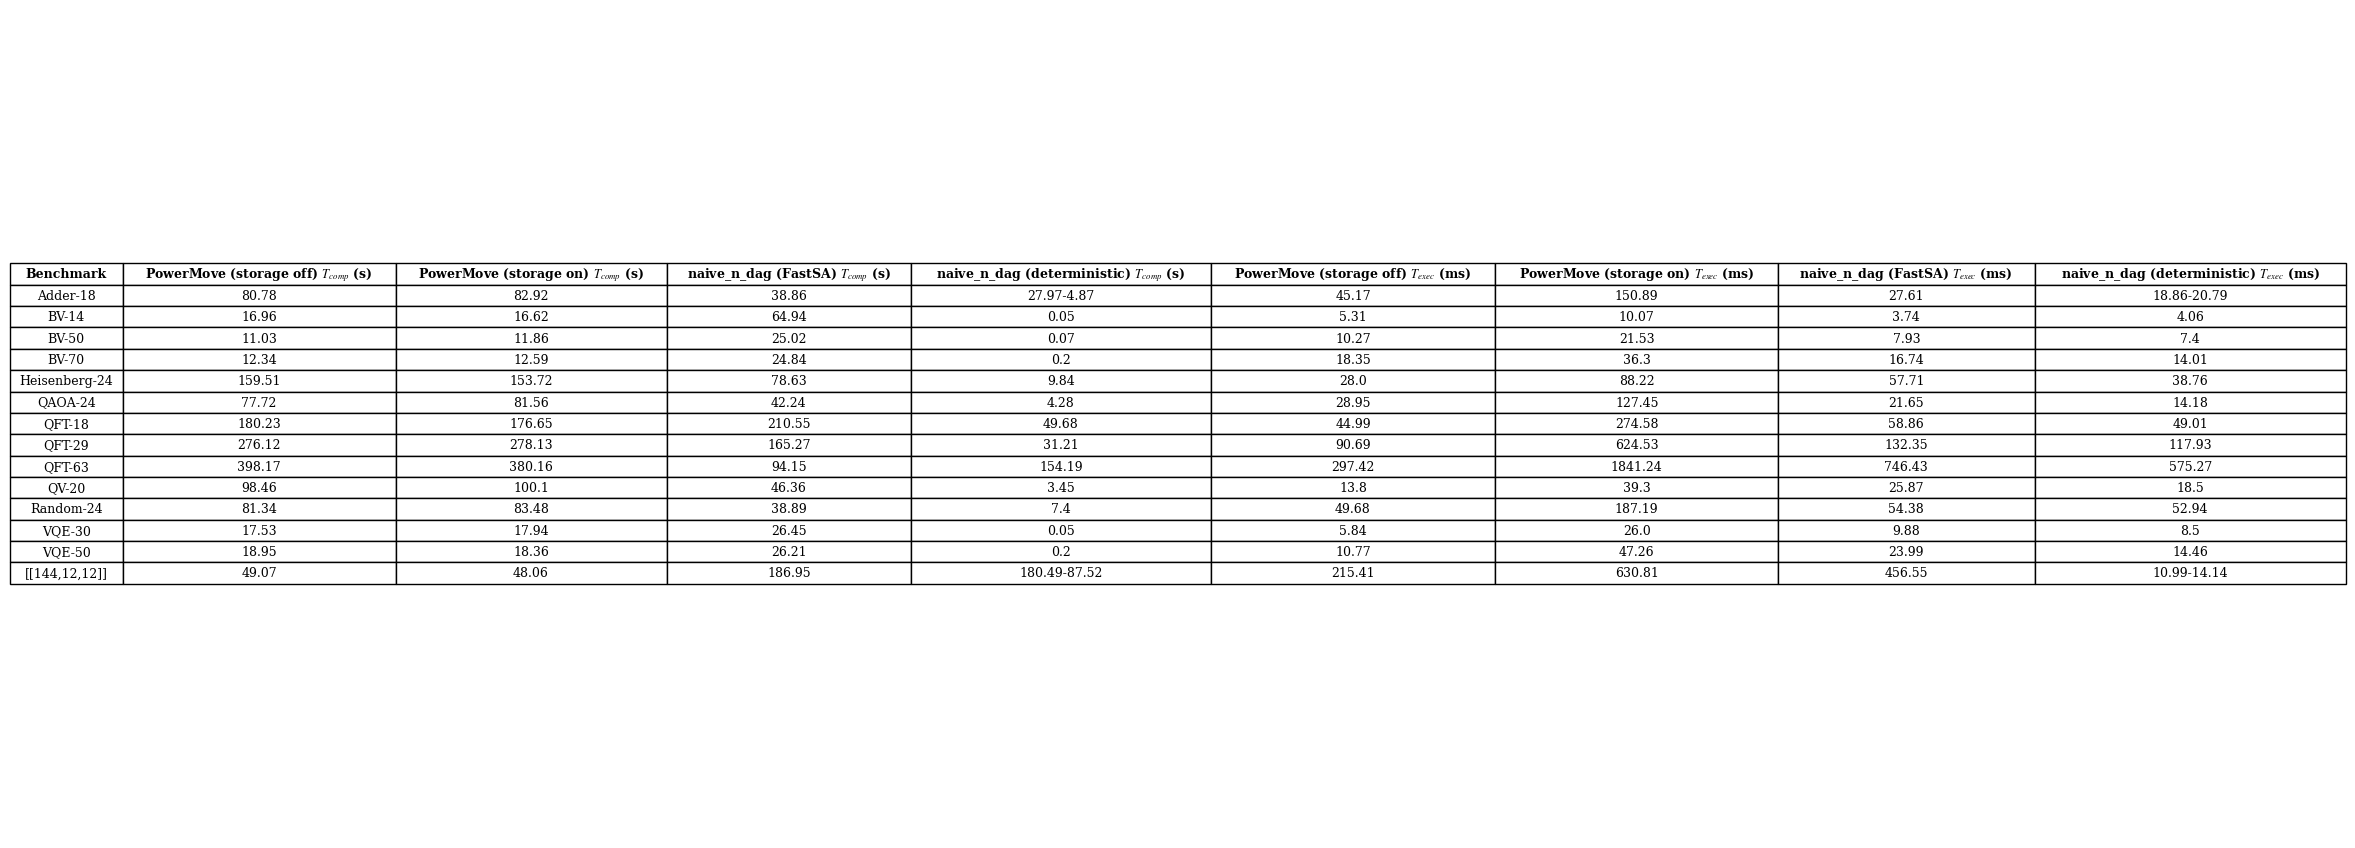

In [3]:
table_df = df[~df["solver"].isin(["naive_n_dag (random)", "Enola","naive_dag"])]
pivot_df = table_df[table_df["variant"] != "fast"].pivot_table(
    index="Benchmark", columns="solver", values=["Texec_ms", "Tcomp_s"], aggfunc="first"
).round(2).astype(object)
# A screened run and its no-screen twin share one cell: "slow-fast".
for _, fast in table_df[table_df["variant"] == "fast"].iterrows():
    for metric in ("Texec_ms", "Tcomp_s"):
        slow = pivot_df.loc[fast["Benchmark"], (metric, fast["solver"])]
        pivot_df.loc[fast["Benchmark"], (metric, fast["solver"])] = f"{slow:.2f}-{fast[metric]:.2f}"

pivot_df.columns = [
    f"{solver} " + (r"$T_{exec}$ (ms)" if metric == "Texec_ms" else r"$T_{comp}$ (s)")
    for metric, solver in pivot_df.columns
]
pivot_df = pivot_df.reset_index()

fig, ax = plt.subplots(figsize=(16, len(pivot_df) * 0.6))
ax.axis("off")

table = ax.table(
    cellText=pivot_df.values,
    colLabels=pivot_df.columns,
    loc="center",
    cellLoc="center",
)
table.auto_set_font_size(False)
table.set_fontsize(9)
table.auto_set_column_width(col=list(range(len(pivot_df.columns))))

# Bold header row
for (row, col), cell in table.get_celld().items():
    if row == 0:
        cell.set_text_props(weight="bold")

plt.tight_layout(pad=0.2)
fig.savefig(analysis_out / "summary_table.pdf", bbox_inches="tight")
plt.show()

## 7) AOD loads and unloads

Counts how many times the AOD loads and unloads atoms. naive_n_dag (FastSA and deterministic) is counted from the
schedules written in sections 2 and 3; PowerMove with the storage zone off and on comes from
`benchmarks/output/powermove_aod_transfers.csv` (written by `benchmarks/powermove_transfers.py`). The counts are
written to `analysis_output/aod_transfers.csv`. A deterministic config with a no-screen twin is plotted with its
slow (screened) run, as in section 5.

In [4]:
from collections import Counter

powermove_transfers_csv = repo_root / "benchmarks" / "output" / "powermove_aod_transfers.csv"
if not powermove_transfers_csv.exists():
    raise FileNotFoundError(f"{powermove_transfers_csv.relative_to(repo_root)} not found. Run benchmarks/powermove_transfers.py first.")

load_re = re.compile(r"(?<![a-z])load q\[(\d+)\]")
unload_re = re.compile(r"\bunload q\[(\d+)\]")
transfer_columns = ["load_steps", "unload_steps", "atom_loads", "atom_unloads", "max_loads_one_qubit", "max_unloads_one_qubit"]


def count_transfers(schedule_path: Path) -> dict:
    """Load/unload steps, atom loads/unloads and the most on one qubit in a naive_n_dag schedule."""
    loads, unloads = Counter(), Counter()
    load_steps = unload_steps = 0
    for line in schedule_path.read_text(encoding="utf-8").splitlines():
        # A step's load/unload entries can share a line with moves of atoms already in the AOD.
        step_loads, step_unloads = load_re.findall(line), unload_re.findall(line)
        load_steps += bool(step_loads)
        unload_steps += bool(step_unloads)
        loads.update(map(int, step_loads))
        unloads.update(map(int, step_unloads))
    return {
        "load_steps": load_steps,
        "unload_steps": unload_steps,
        "atom_loads": sum(loads.values()),
        "atom_unloads": sum(unloads.values()),
        "max_loads_one_qubit": max(loads.values(), default=0),
        "max_unloads_one_qubit": max(unloads.values(), default=0),
    }


naive_runs = pd.concat(
    [pd.read_csv(analysis_out / name, encoding="utf-8") for name in ("bb144_batch_timings.csv", "general_batch_timings.csv")],
    ignore_index=True,
)
naive_runs = naive_runs[(naive_runs["solver"] == "naive_n_dag") & naive_runs["placement"].isin(["fastsa", "deterministic"])]

transfer_records = []
for _, run in naive_runs.iterrows():
    transfer_records.append({
        "Benchmark": run["Benchmark"],
        "solver": "naive_n_dag (FastSA)" if run["placement"] == "fastsa" else "naive_n_dag (deterministic)",
        "variant": run["variant"] if isinstance(run["variant"], str) else "",
        **count_transfers(repo_root / run["output_file"]),
    })
for _, row in pd.read_csv(powermove_transfers_csv, encoding="utf-8").iterrows():
    transfer_records.append({
        "Benchmark": row["Benchmark"],
        "solver": f"PowerMove (storage {row['storage']})",
        "variant": "",
        **{column: row[column] for column in transfer_columns},
    })

transfers_df = pd.DataFrame(transfer_records)
transfers_df.to_csv(analysis_out / "aod_transfers.csv", index=False)
transfers_df

,Benchmark,solver,variant,load_steps,unload_steps,atom_loads,atom_unloads,max_loads_one_qubit,max_unloads_one_qubit
0,"[[144,12,12]]",naive_n_dag (FastSA),,62,64,564,564,4,4
1,"[[144,12,12]]",naive_n_dag (deterministic),slow,2,2,144,144,1,1
2,"[[144,12,12]]",naive_n_dag (deterministic),fast,2,2,144,144,1,1
3,BV-14,naive_n_dag (FastSA),,1,1,1,1,1,1
4,BV-14,naive_n_dag (deterministic),,1,1,1,1,1,1
5,BV-50,naive_n_dag (FastSA),,1,1,1,1,1,1
6,BV-50,naive_n_dag (deterministic),,1,1,1,1,1,1
7,BV-70,naive_n_dag (FastSA),,1,1,1,1,1,1
8,BV-70,naive_n_dag (deterministic),,1,1,1,1,1,1
9,QFT-18,naive_n_dag (FastSA),,28,23,61,61,5,5


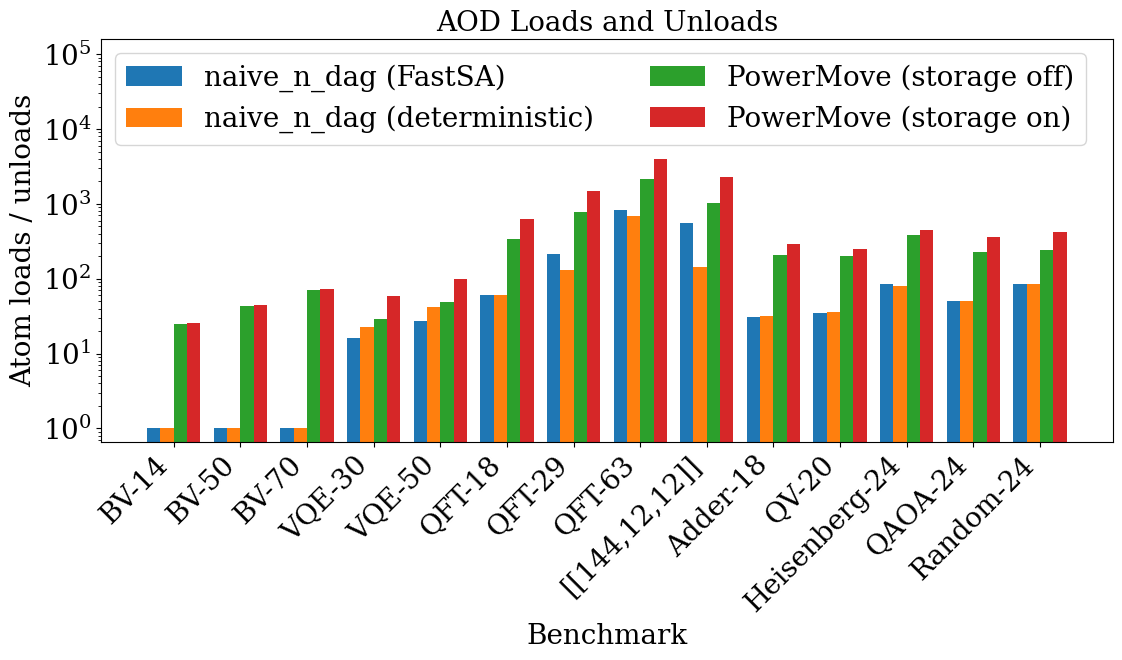

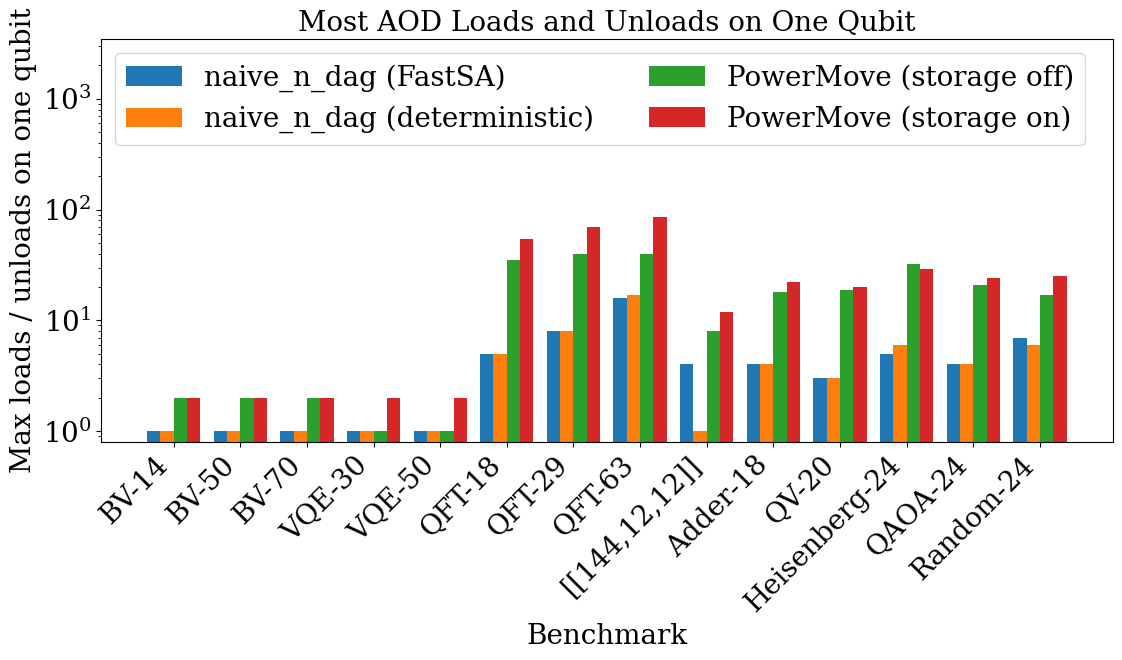

In [5]:
transfer_solvers = ["naive_n_dag (FastSA)", "naive_n_dag (deterministic)", "PowerMove (storage off)", "PowerMove (storage on)"]
transfer_benchmarks = [*group1, *group2, *group3]
plot_transfers_df = transfers_df[transfers_df["variant"] != "fast"]


def plot_transfers(columns, ylabel, title, output_file):
    """Grouped bars per benchmark: the larger of the two columns (loads, unloads) for each solver."""
    x = np.arange(len(transfer_benchmarks))
    width = 0.8 / len(transfer_solvers)

    fig, ax = plt.subplots(figsize=(FINAL_FIG_WIDTH, 7.0))
    top = 1
    for i, solver in enumerate(transfer_solvers):
        values = []
        for bench in transfer_benchmarks:
            row = plot_transfers_df[(plot_transfers_df["Benchmark"] == bench) & (plot_transfers_df["solver"] == solver)]
            values.append(row[columns].max(axis=1).values[0] if not row.empty else 0)
        ax.bar(x + i * width, values, width, label=solver)
        top = max(top, *values)

    ax.set_yscale("log")  # the counts span 1 to a few thousand
    ax.set_ylim(top=top * 40)  # room for the legend above the bars
    ax.set_xlabel("Benchmark")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.set_xticks(x + width * (len(transfer_solvers) - 1) / 2)
    ax.set_xticklabels(transfer_benchmarks, rotation=45, ha="right")
    ax.legend(ncol=2, loc="upper left")

    fig.tight_layout()
    fig.savefig(analysis_out / output_file, bbox_inches="tight")
    plt.show()


plot_transfers(["atom_loads", "atom_unloads"], "Atom loads / unloads", "AOD Loads and Unloads", "AOD_Transfers.pdf")
plot_transfers(["max_loads_one_qubit", "max_unloads_one_qubit"], "Max loads / unloads on one qubit",
               "Most AOD Loads and Unloads on One Qubit", "AOD_Transfers_Max_Qubit.pdf")